# Semana 8 — Máximos, mínimos y ceros de una función

**Física Computacional — 106018C** · Lenguaje: **Fortran y Python**

En la clase se presentan la teoría: la radiación de Planck, los métodos para hallar ceros y la búsqueda de máximos como ceros de la derivada. Este notebook contiene los programas de los métodos, aplicados a ejemplos con raíz conocida, tres ejercicios de calentamiento y, al final, el **Taller 8**.

La semana se reparte entre los dos lenguajes: los **métodos para hallar ceros** se programan en Fortran y la **búsqueda de máximos con spline** en Python.

**Objetivos de la sesión**

1. Localizar los ceros de una función con un barrido de cambios de signo sobre una malla.
2. Programar los métodos de bisección y Newton-Raphson, y completar el de la secante.
3. Medir el orden de convergencia de cada método a partir de los errores sucesivos.
4. Reconocer las condiciones en que cada método falla y elegir un criterio de parada.
5. Hallar un máximo como cero de la derivada numérica y distinguirlo de un mínimo.
6. Interpolar una derivada con un spline cúbico y comparar la precisión con la de la malla.

<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**Alcance.** La función cuyo cero se busca se escribe dentro de un módulo. Pasar una función como argumento de otra requiere bloques `interface`, que se ven en el Capítulo 4.

</div>

In [1]:
# Preparación: bibliotecas de Python y colores del curso
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

AZUL, DORADO, ROJO, VERDE, GRIS = "#162A54", "#C9972C", "#B02A20", "#2E7D32", "#7F7F7F"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Comprobación del compilador de Fortran
!gfortran --version | head -n 1

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


## 1. Ceros de una función

Un **cero** o **raíz** de una función $f(x)$ es un valor $\alpha$ tal que

$$f(\alpha) = 0 .$$

Existen fórmulas exactas para unas pocas familias de funciones: la fórmula cuadrática para $ax^2 + bx + c$, o la factorización en casos particulares, como $x^3 - 6x^2 + 11x - 6 = (x-1)(x-2)(x-3)$. Para la mayoría de las ecuaciones que aparecen en física, como $x = 5(1 - e^{-x})$, no hay fórmula en términos de funciones elementales: la raíz se aproxima con un método iterativo, que parte de un valor inicial y produce una sucesión $x_0, x_1, x_2, \dots$ que se acerca a $\alpha$.

### 1.1 Localización de las raíces

Todos los métodos necesitan saber aproximadamente dónde está la raíz. El punto de partida es el **teorema del valor intermedio**: si $f$ es continua en $[a, b]$ y $f(a)\,f(b) < 0$, entonces $f$ tiene al menos un cero entre $a$ y $b$. El intervalo $[a, b]$ se llama **intervalo de arranque**.

En la práctica, los intervalos de arranque se encuentran evaluando $f$ en una malla y buscando los pares de puntos vecinos con signos distintos. Es una operación sobre arreglos, como las de la Semana 7. La ecuación de ejemplo de esta sección es

$$f(x) = x^6 - x - 1 = 0 ,$$

que tiene dos raíces reales: $\alpha_1 = -0.7780895987$ y $\alpha_2 = 1.134724138$.

cambio de signo en [-0.80, -0.70]:  f =   0.0621,  -0.1824
cambio de signo en [ 1.10,  1.20]:  f =  -0.3284,   0.7860


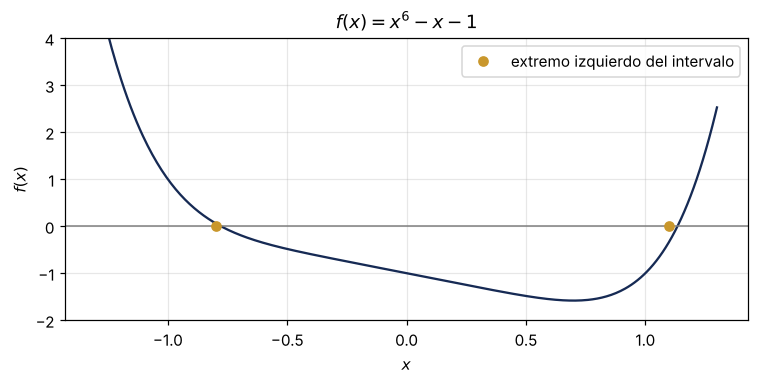

In [2]:
def f(x):
    """Función de ejemplo: f(x) = x**6 - x - 1."""
    return x**6 - x - 1

x = np.linspace(-1.5, 1.5, 31)            # malla gruesa, paso 0.1
y = f(x)

# Índices i tales que y[i] e y[i+1] tienen signos distintos
cambios = np.where(y[:-1]*y[1:] < 0)[0]
for i in cambios:
    print(f"cambio de signo en [{x[i]:5.2f}, {x[i+1]:5.2f}]:  f = {y[i]:8.4f}, {y[i+1]:8.4f}")

xf = np.linspace(-1.3, 1.3, 400)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(xf, f(xf), color=AZUL)
ax.axhline(0, color=GRIS, lw=1)
ax.plot(x[cambios], 0*cambios, "o", color=DORADO, label="extremo izquierdo del intervalo")
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$"); ax.set_ylim(-2, 4); ax.legend()
ax.set_title(r"$f(x) = x^6 - x - 1$")
plt.tight_layout(); plt.show()

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** concluir que no hay raíz porque el barrido no encontró un cambio de signo. Una raíz doble, como la de $f(x) = (x-1)^2$, toca el eje sin cruzarlo, y dos raíces más cercanas que el paso de la malla producen dos cambios de signo que se cancelan entre puntos vecinos. Repita el barrido con una malla más fina y grafique la función; refinar no revela una raíz doble.

</div>

## 2. Método de bisección

El método parte de un intervalo $[a, b]$ con $f(a)\,f(b) < 0$. En cada iteración se calcula el punto medio $c = (a + b)/2$, se conserva la mitad del intervalo donde $f$ cambia de signo y se repite.

**Algoritmo**, con tolerancia $\varepsilon$ sobre el error absoluto de la raíz:

1. Verificar que $f(a)\,f(b) < 0$; si no se cumple, detenerse con un mensaje.
2. Calcular $c = (a + b)/2$.
3. Si $b - c \le \varepsilon$, aceptar $c$ como raíz y terminar.
4. Si $f(a)\,f(c) \le 0$, hacer $b = c$; en caso contrario, hacer $a = c$. Volver al paso 2.

**Cota del error.** Sea $\alpha$ la raíz y sean $a$, $b$ los extremos del intervalo inicial. Cada iteración divide el intervalo a la mitad, así que el punto medio $c_n$ de la iteración $n$ cumple

$$|\alpha - c_n| \le \frac{b - a}{2^n} ,$$

y el número de iteraciones necesario para una tolerancia $\varepsilon$ se conoce **antes** de ejecutar:

$$n \ge \frac{\log\left[(b - a)/\varepsilon\right]}{\log 2} .$$

Con $[a, b] = [1, 2]$ y $\varepsilon = 10^{-3}$, $n \ge 9.97$: 10 iteraciones.

El módulo siguiente contiene la función de ejemplo y su derivada. Los programas de las secciones 2 a 4 lo usan; para resolver otra ecuación basta cambiar el módulo.

In [3]:
%%writefile modulo_ejemplo.f90
! ============================================================
! Módulo:    modulo_ejemplo
! Propósito: función de ejemplo f(x) = x**6 - x - 1 y su derivada.
! ============================================================
module modulo_ejemplo
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), parameter :: raiz_exacta = 1.134724138401519_dp   ! solo para medir errores
contains

  ! f: función cuyo cero se busca
  real(dp) function f(x)
    real(dp), intent(in) :: x
    f = x**6 - x - 1.0_dp
  end function f

  ! df: derivada analítica de f, f'(x) = 6 x**5 - 1
  real(dp) function df(x)
    real(dp), intent(in) :: x
    df = 6.0_dp*x**5 - 1.0_dp
  end function df

end module modulo_ejemplo

Writing modulo_ejemplo.f90


In [4]:
%%writefile ejemplo_biseccion.f90
! ============================================================
! Programa:  ejemplo_biseccion
! Propósito: hallar la raíz de f en [1, 2] por bisección.
! Salida:    tabla en pantalla; errores_biseccion.dat
! ============================================================
program ejemplo_biseccion
  use modulo_ejemplo, only: dp, f, raiz_exacta
  implicit none
  real(dp), parameter :: tol = 1.0e-3_dp
  integer, parameter :: max_iter = 100      ! protección contra ciclos sin fin
  real(dp) :: a, b, c
  integer :: n, u

  a = 1.0_dp
  b = 2.0_dp
  ! --- Paso 1: el intervalo debe contener un cambio de signo
  if (f(a)*f(b) >= 0.0_dp) stop 'bisección: f(a) y f(b) no tienen signos distintos'

  open(newunit=u, file='errores_biseccion.dat', status='replace', action='write')
  print '(a)', '  n        a        b        c       b-c       f(c)'
  do n = 1, max_iter
     c = 0.5_dp*(a + b)                     ! paso 2: punto medio
     print '(i3,3f9.4,f10.5,f11.4)', n, a, b, c, b - c, f(c)
     write(u, '(i4,es14.6)') n, abs(c - raiz_exacta)
     if (b - c <= tol) exit                 ! paso 3: criterio de parada
     if (f(a)*f(c) <= 0.0_dp) then          ! paso 4: mitad con cambio de signo
        b = c
     else
        a = c
     end if
  end do
  close(u)
  print '(/,a,f8.4,a,i0,a)', 'Raíz aproximada: ', c, ' en ', n, ' iteraciones'
  print '(a,es9.2)', 'Error real:      ', abs(c - raiz_exacta)
end program ejemplo_biseccion

Writing ejemplo_biseccion.f90


In [5]:
!gfortran -fcheck=bounds -o ejemplo_biseccion modulo_ejemplo.f90 ejemplo_biseccion.f90 && ./ejemplo_biseccion

  n        a        b        c       b-c       f(c)
  1   1.0000   2.0000   1.5000   0.50000     8.8906
  2   1.0000   1.5000   1.2500   0.25000     1.5647
  3   1.0000   1.2500   1.1250   0.12500    -0.0977
  4   1.1250   1.2500   1.1875   0.06250     0.6167
  5   1.1250   1.1875   1.1562   0.03125     0.2333
  6   1.1250   1.1562   1.1406   0.01562     0.0616
  7   1.1250   1.1406   1.1328   0.00781    -0.0196
  8   1.1328   1.1406   1.1367   0.00391     0.0206
  9   1.1328   1.1367   1.1348   0.00195     0.0004
 10   1.1328   1.1348   1.1338   0.00098    -0.0096

Raíz aproximada:   1.1338 en 10 iteraciones
Error real:       9.35E-04


Después de 10 iteraciones, $b - c = 0.00098 < 0.001$, y el error real es $9.4\times10^{-4}$: la cota se cumple. La columna $f(c)$ muestra que la cercanía a la raíz no mejora de manera regular: en la iteración 9, $c = 1.1348$ estaba mucho más cerca que en la 10, con $f(c) = 0.0004$ frente a $-0.0096$.

**Propiedades del método**

- Si $f$ es continua y el intervalo de arranque es válido, **siempre converge**.
- El error garantizado se reduce a la mitad en cada iteración: la convergencia es **lineal**, con razón $1/2$. Se gana una cifra decimal cada 3.3 iteraciones aproximadamente.
- No aprovecha la forma de la función, solo el signo de sus valores.
- Encuentra una sola raíz por intervalo y no detecta las raíces de multiplicidad par, porque ahí $f$ no cambia de signo.

## 3. Método de Newton-Raphson

Se parte de una estimación $x_n$ de la raíz. La función se reemplaza por su recta tangente en $x_n$ y la siguiente estimación $x_{n+1}$ es el punto donde esa recta cruza el eje $x$. La recta tangente es

$$y = f(x_n) + f'(x_n)\,(x - x_n) ,$$

donde $f(x_n)$ es el valor de la función en la estimación actual y $f'(x_n)$ es su derivada, la pendiente de la tangente. Con $y = 0$:

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)} .$$

**Error.** Sea $\alpha$ la raíz. La serie de Taylor de $f$ alrededor de $x_n$, evaluada en $\alpha$, es

$$0 = f(\alpha) = f(x_n) + (\alpha - x_n)\,f'(x_n) + \frac{1}{2}(\alpha - x_n)^2 f''(c_n) ,$$

con $c_n$ algún punto entre $\alpha$ y $x_n$. Dividiendo por $f'(x_n)$ y usando la fórmula de la iteración:

$$\alpha - x_{n+1} = (\alpha - x_n)^2\left[\frac{-f''(c_n)}{2 f'(x_n)}\right] .$$

El error de la iteración siguiente es proporcional al **cuadrado** del error actual: la convergencia es **cuadrática**, y el número de cifras correctas se duplica aproximadamente en cada paso, siempre que la estimación esté cerca de la raíz y $f'(\alpha) \neq 0$.

**Estimación del error.** La raíz no se conoce, pero cerca de ella $\alpha - x_n \approx -f(x_n)/f'(x_n) = x_{n+1} - x_n$. La diferencia entre dos iteraciones consecutivas mide el error de la anterior, y esa es la cantidad que se usa como criterio de parada.

In [6]:
%%writefile ejemplo_newton.f90
! ============================================================
! Programa:  ejemplo_newton
! Propósito: hallar la raíz de f partiendo de x0 = 1.5 con el
!            método de Newton-Raphson.
! Salida:    tabla en pantalla; errores_newton.dat
! ============================================================
program ejemplo_newton
  use modulo_ejemplo, only: dp, f, df, raiz_exacta
  implicit none
  real(dp), parameter :: tol = 1.0e-10_dp
  integer, parameter :: max_iter = 50
  real(dp) :: x, paso, dfx
  integer :: n, u

  x = 1.5_dp                                ! estimación inicial x0
  open(newunit=u, file='errores_newton.dat', status='replace', action='write')
  write(u, '(i4,es14.6)') 0, abs(x - raiz_exacta)
  print '(a)', ' n       x_n              f(x_n)     x_n - x_(n-1)   alfa - x_(n-1)'
  print '(i2,f17.12,es13.3)', 0, x, f(x)
  do n = 1, max_iter
     dfx = df(x)
     if (abs(dfx) < tiny(1.0_dp)) stop 'Newton: derivada nula'
     paso = -f(x)/dfx                       ! corrección de Newton
     x = x + paso
     print '(i2,f17.12,es13.3,2es15.3)', n, x, f(x), paso, raiz_exacta - (x - paso)
     write(u, '(i4,es14.6)') n, abs(x - raiz_exacta)
     if (abs(paso) < tol) exit              ! dos iteraciones ya coinciden
  end do
  close(u)
  if (n > max_iter) print '(a)', 'Newton: no convergió en max_iter iteraciones'
  print '(a,es10.2)', 'Residuo final |f(x)|: ', abs(f(x))    ! revisión del resultado
end program ejemplo_newton

Writing ejemplo_newton.f90


In [7]:
!gfortran -fcheck=bounds -o ejemplo_newton modulo_ejemplo.f90 ejemplo_newton.f90 && ./ejemplo_newton

 n       x_n              f(x_n)     x_n - x_(n-1)   alfa - x_(n-1)
 0   1.500000000000    8.891E+00
 1   1.300490883590    2.537E+00     -1.995E-01     -3.653E-01
 2   1.181480416403    5.385E-01     -1.190E-01     -1.658E-01
 3   1.139455590276    4.924E-02     -4.202E-02     -4.676E-02
 4   1.134777625237    5.503E-04     -4.678E-03     -4.731E-03
 5   1.134724145316    7.114E-08     -5.348E-05     -5.349E-05
 6   1.134724138402    1.110E-15     -6.915E-09     -6.915E-09
 7   1.134724138402    1.110E-15     -1.079E-16     -6.661E-16
Residuo final |f(x)|:   1.11E-15


Las dos últimas columnas casi coinciden desde la cuarta iteración: $x_n - x_{n-1}$ estima bien el error de $x_{n-1}$. El error pasa de $4.7\times10^{-3}$ a $5.4\times10^{-5}$ y a $6.9\times10^{-9}$: el exponente se duplica. Comparado con bisección, Newton usa dos evaluaciones por iteración ($f$ y $f'$) y necesita conocer $f'$.

### 3.1 Dependencia del valor inicial

Newton no tiene garantía de convergencia. Si $x_0$ está lejos de la raíz, la tangente puede enviar la iteración a cualquier parte. El ejemplo clásico es

$$f(x) = \tan(\pi x) - x - 6 ,$$

que tiene una raíz en $\alpha = 0.45104726$ y un polo en $x = 0.5$, donde $\tan(\pi x)$ diverge. El programa siguiente parte de tres valores iniciales. La función se escribe en el mismo programa porque solo se usa aquí.

In [8]:
%%writefile ejemplo_newton_falla.f90
! ============================================================
! Programa:  ejemplo_newton_falla
! Propósito: efecto del valor inicial en el método de Newton
!            para f(x) = tan(pi x) - x - 6.
! Salida:    tabla en pantalla
! ============================================================
program ejemplo_newton_falla
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), parameter :: pi = 4*atan(1.0_dp)
  real(dp) :: x(3)                          ! una estimación por columna
  integer :: n

  x = [0.48_dp, 0.40_dp, 0.01_dp]           ! tres valores iniciales
  print '(a)', ' n    x0 = 0.48     x0 = 0.40     x0 = 0.01'
  do n = 1, 11
     x = x - f(x)/df(x)                     ! una iteración de las tres columnas
     print '(i2,3f14.7)', n, x
  end do

contains

  elemental real(dp) function f(x)
    real(dp), intent(in) :: x
    f = tan(pi*x) - x - 6.0_dp
  end function f

  ! derivada analítica: pi/cos(pi x)**2 - 1
  elemental real(dp) function df(x)
    real(dp), intent(in) :: x
    df = pi/cos(pi*x)**2 - 1.0_dp
  end function df

end program ejemplo_newton_falla

Writing ejemplo_newton_falla.f90


In [9]:
!gfortran -fcheck=bounds -o ejemplo_newton_falla ejemplo_newton_falla.f90 && ./ejemplo_newton_falla

 n    x0 = 0.48     x0 = 0.40     x0 = 0.01
 1     0.4681700     0.5041505     2.7976098
 2     0.4570355     0.5086528     5.2724798
 3     0.4517795     0.5188342     6.8756531
 4     0.4510582     0.5449097    11.8440960
 5     0.4510473     0.6309631    17.9002511
 6     0.4510473     1.1095881    27.7017782
 7     0.4510473     3.7617354    32.1092497
 8     0.4510473     5.9650405    46.9558479
 9     0.4510473    11.5046972    71.0592445
10     0.4510473    11.5106073   105.1788331
11     0.4510473    11.5274001   137.8232682


Solo la primera columna converge a $0.45104726$. Las otras dos parten de una región donde la tangente cruza el eje lejos de la raíz: la sucesión salta entre ramas de la tangente y no se estabiliza, aunque cada iteración se calcula sin error de programación.

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** usar Newton sin límite de iteraciones y sin revisar el resultado. El método puede diverger, saltar entre ramas o converger a una raíz distinta de la buscada. Fije siempre un máximo de iteraciones y compruebe que $|f(x)|$ es pequeño al terminar.

</div>

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Unas pocas iteraciones de bisección mejoran el valor inicial de Newton, pero no garantizan su convergencia. Para conservar la garantía, un método híbrido mantiene el intervalo con cambio de signo y vuelve a bisección cuando el paso de Newton no es adecuado.

</div>

## 4. Método de la secante, orden de convergencia y criterios de parada

### 4.1 Método de la secante

Cuando $f'$ no se conoce o es costosa, la pendiente de la tangente se reemplaza por la de la recta secante que pasa por las dos últimas estimaciones:

$$x_{n+1} = x_n - f(x_n)\,\frac{x_n - x_{n-1}}{f(x_n) - f(x_{n-1})} ,$$

donde $x_n$ y $x_{n-1}$ son las dos últimas estimaciones y el cociente es el inverso de la pendiente de la secante. El método necesita dos valores iniciales, usa una sola evaluación nueva de $f$ por iteración y, para una raíz simple, su orden de convergencia es $p = (1 + \sqrt{5})/2 \approx 1.618$: más lento que Newton por iteración, más rápido que bisección y, cuando evaluar $f'$ cuesta tanto como evaluar $f$, más económico que Newton por evaluación.

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 1 (no calificado): método de la secante**

El programa `ejercicio_secante.f90` tiene los dos valores iniciales $x_0 = 1.0$ y $x_1 = 2.0$ de $f(x) = x^6 - x - 1$ y escribe la tabla de iteraciones.

1. Obtenga cada nueva estimación con la fórmula de la sección 4.1.
2. Detenga el ciclo cuando dos estimaciones consecutivas difieran en menos de la tolerancia.

**Debe obtener:** $x_2 = 1.0161290$, $x_3 = 1.0306748$, $x_4 = 1.1756889$ y la raíz $1.134724138$ en $x_{10}$. Los errores de las últimas iteraciones son $2.9\times10^{-5}$ ($x_7$), $7.3\times10^{-8}$ ($x_8$) y $5.0\times10^{-12}$ ($x_9$).

</div>

In [10]:
%%writefile ejercicio_secante.f90
! ============================================================
! Programa:  ejercicio_secante   (Ejercicio de calentamiento 1)
! Propósito: raíz de f con el método de la secante.
! Salida:    tabla en pantalla; errores_secante.dat
! ============================================================
program ejercicio_secante
  use modulo_ejemplo, only: dp, f, raiz_exacta
  implicit none
  real(dp), parameter :: tol = 1.0e-10_dp
  integer, parameter :: max_iter = 15
  real(dp) :: x0, x1, x_nuevo
  integer :: n, u

  x0 = 1.0_dp
  x1 = 2.0_dp
  open(newunit=u, file='errores_secante.dat', status='replace', action='write')
  print '(a)', ' n      x_n             error'
  do n = 2, max_iter
     ! TODO: obtenga la nueva estimación (sección 4.1) y actualice x0 y x1
     x_nuevo = x1
     print '(i2,f17.12,es12.3)', n, x_nuevo, abs(x_nuevo - raiz_exacta)
     write(u, '(i4,es14.6)') n, abs(x_nuevo - raiz_exacta)
     ! TODO: detenga el ciclo según el criterio de parada del enunciado
  end do
  close(u)
end program ejercicio_secante

Writing ejercicio_secante.f90


In [ ]:
!gfortran -fcheck=bounds -o ejercicio_secante modulo_ejemplo.f90 ejercicio_secante.f90 && ./ejercicio_secante

### 4.2 Orden de convergencia

Se dice que un método tiene **orden** $p$ si cerca de la raíz el error $e_n = |\alpha - x_n|$ cumple

$$e_{n+1} \approx C\,e_n^{\,p} ,$$

donde $C$ es una constante que depende de la función y $p$ es el orden: $p = 1$ para la cota de bisección, $p \approx 1.618$ en la secante y $p = 2$ en Newton. Tomando logaritmos en tres iteraciones consecutivas se obtiene $p$ sin conocer $C$:

$$p \approx \frac{\ln(e_{n+1}/e_n)}{\ln(e_n/e_{n-1})} .$$

La celda siguiente lee los archivos que escribieron los programas de bisección y Newton y, si ya se resolvió el Ejercicio 1, también el de la secante. El orden se estima con la última terna de errores que no esté dominada por el redondeo.

   secante: sin convergencia todavía
    Newton: orden estimado p = 2.00


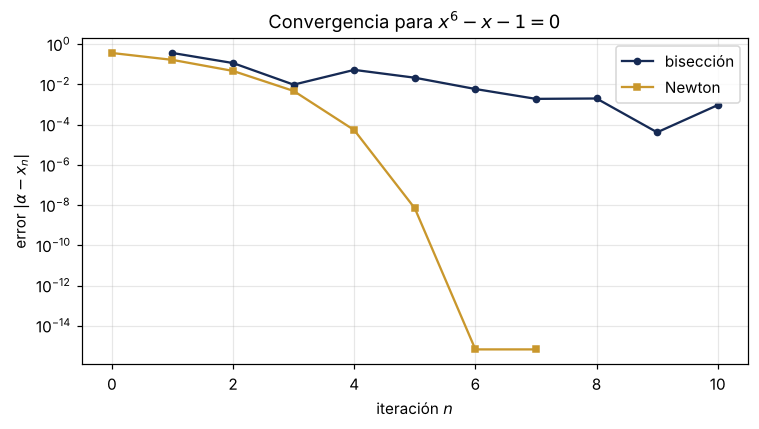

In [12]:
import os

def orden(errores):
    """Estimación del orden p con la última terna de errores mayores que 1e-13."""
    e = errores[errores > 1e-13]
    return np.log(e[-1]/e[-2])/np.log(e[-2]/e[-3])

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, archivo, color, marca in [("bisección", "errores_biseccion.dat", AZUL, "o"),
                                      ("secante", "errores_secante.dat", VERDE, "^"),
                                      ("Newton", "errores_newton.dat", DORADO, "s")]:
    if not os.path.exists(archivo) or os.path.getsize(archivo) == 0:
        print(f"{nombre:>10}: sin datos todavía")
        continue
    n, e = np.loadtxt(archivo, unpack=True)
    if np.any(np.isnan(e)) or e[-1] > 1e-3 and nombre != "bisección":
        print(f"{nombre:>10}: sin convergencia todavía")
        continue
    ax.semilogy(n, np.maximum(e, 1e-17), marca + "-", ms=4, color=color, label=nombre)
    if nombre != "bisección":                  # ver el recuadro siguiente
        print(f"{nombre:>10}: orden estimado p = {orden(e):.2f}")
ax.set_xlabel("iteración $n$"); ax.set_ylabel(r"error $|\alpha - x_n|$")
ax.set_title(r"Convergencia para $x^6 - x - 1 = 0$"); ax.legend()
plt.tight_layout(); plt.show()

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**Evite** medir el orden de bisección con errores consecutivos: su error real oscila, porque el punto medio puede caer muy cerca de la raíz por casualidad. Lo que se reduce a la mitad en cada iteración es la **cota** $(b-a)/2^n$, no el error real.

</div>

### 4.3 Criterios de parada

Un método iterativo necesita decidir cuándo terminar sin conocer la raíz. Los criterios habituales son:

| Criterio | Condición | Qué controla |
|---|---|---|
| Intervalo | $b - c \le \varepsilon$ | Error garantizado en bisección |
| Paso | $\lvert x_{n+1} - x_n\rvert < \varepsilon$ | Error estimado en Newton y secante |
| Residuo | $\lvert f(x_n)\rvert < \varepsilon$ | Qué tan cerca de cero está $f$ |
| Iteraciones | $n \ge n_{\max}$ | Evita un ciclo sin fin |

Un residuo pequeño no implica un error pequeño: si $f$ es casi plana cerca de la raíz, $f(x)$ puede ser diminuto lejos de $\alpha$. Un paso pequeño tampoco asegura el éxito. Por esa razón se usa el criterio de paso o de intervalo y se revisa el residuo al final.

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 2 (no calificado): todas las raíces de un polinomio**

El polinomio $f(x) = x^3 + 2x^2 - 3x - 1$ tiene tres raíces reales. En `ejercicio_barrido.f90`, la función ya está en el programa.

1. Evalúe $f$ en una malla de 81 puntos en $[-4, 4]$ y localice los intervalos con cambio de signo, con secciones de arreglo o con un ciclo.
2. Refine cada intervalo por bisección con tolerancia $10^{-3}$. Escriba la bisección dentro del ciclo que recorre los intervalos.

**Debe obtener** tres raíces cercanas a $-2.912$, $-0.287$ y $1.199$.

**Práctica adicional, con los mismos métodos:** $e^x - x - 2 = 0$ tiene una raíz $\alpha = 1.146193$ en $(1, 2)$; estime primero las iteraciones de bisección para $\varepsilon = 10^{-3}$. La función $e^x - 3x$ tiene raíces $0.619061$ y $1.512135$; compruebe a cuál llega Newton desde $x_0 = 0$ y desde $x_0 = 2$.

</div>

In [13]:
%%writefile ejercicio_barrido.f90
! ============================================================
! Programa:  ejercicio_barrido   (Ejercicio de calentamiento 2)
! Propósito: localizar y refinar todas las raíces reales de f.
! Salida:    en pantalla
! ============================================================
program ejercicio_barrido
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: n = 81              ! puntos de la malla
  real(dp), parameter :: tol = 1.0e-3_dp
  real(dp) :: x(n), y(n), a, b, c
  integer :: i

  ! TODO: construya la malla, localice los cambios de signo y
  !       refine cada intervalo por bisección (secciones 1.1 y 2)

contains

  ! f: polinomio de grado 3 (elemental: admite un arreglo como argumento)
  elemental real(dp) function f(x)
    real(dp), intent(in) :: x
    f = x**3 + 2.0_dp*x**2 - 3.0_dp*x - 1.0_dp
  end function f

end program ejercicio_barrido

Writing ejercicio_barrido.f90


In [ ]:
!gfortran -fcheck=bounds -o ejercicio_barrido ejercicio_barrido.f90 && ./ejercicio_barrido

## 5. Máximos y mínimos como ceros de la derivada (Python)

En un máximo o en un mínimo interior de una función suave, la derivada es cero. Los ceros de $f'$ son los candidatos a extremos:

$$f'(x^*) = 0, \qquad f''(x^*) < 0 \ \ \text{(máximo)}, \qquad f''(x^*) > 0 \ \ \text{(mínimo)},$$

donde $x^*$ es la posición del extremo. Estas condiciones sobre $f''$ son suficientes, no necesarias: $f' = 0$ no distingue entre un máximo y un mínimo, y si $f''(x^*) = 0$ el criterio no decide. Por ejemplo, $x^4$ tiene un mínimo en cero y $x^3$ no tiene extremo allí.

El ejemplo de esta sección es una función proporcional a la distribución de rapideces de Maxwell-Boltzmann en unidades reducidas:

$$f(v) = v^2\,e^{-v^2/2} ,$$

donde $v$ es la rapidez, medida en unidades de $\sqrt{k_B T/m}$, con $k_B$ la constante de Boltzmann, $T$ la temperatura y $m$ la masa de la molécula. El factor $v^2$ cuenta los estados con rapidez $v$ y el exponencial es el factor de Boltzmann.

### 5.1 Máximo analítico

Derivando,

$$f'(v) = \left(2v - v^3\right)e^{-v^2/2} = 0 \quad\Longrightarrow\quad v^* = \sqrt{2} = 1.414214 ,$$

que es la **rapidez más probable**. Este valor sirve de referencia para medir los errores de los métodos numéricos.

### 5.2 Máximo sobre la malla y cambio de signo de la derivada numérica

Con datos en una malla de paso $h$ hay tres aproximaciones, de menor a mayor esfuerzo:

1. **Mayor valor del arreglo**, con `np.argmax`. Su error es de orden $h$ y no se reduce de manera regular al refinar la malla.
2. **Cero lineal de la derivada numérica.** Con la derivada central $d_i$, se localiza el par de puntos donde $d$ pasa de positiva a negativa y se interpola linealmente entre ellos.
3. **Cero del spline de la derivada numérica** (sección 5.3).

In [15]:
def maxwell(v):
    """Distribución de Maxwell-Boltzmann en unidades reducidas."""
    return v**2*np.exp(-v**2/2)

def derivada_central(y, h):
    """Derivada central en los puntos interiores de una malla de paso h."""
    return (y[2:] - y[:-2])/(2*h)

def cero_lineal(x, d):
    """Interpola linealmente el primer paso de d de positiva a negativa."""
    i = np.where((d[:-1] > 0) & (d[1:] <= 0))[0][0]
    return x[i] - d[i]*(x[i+1] - x[i])/(d[i+1] - d[i])

h = 0.2
v = np.arange(0.0, 6.0 + h/2, h)     # malla de la distribución
y = maxwell(v)
d = derivada_central(y, h)           # derivada en v[1:-1]

v_ref = np.sqrt(2)
print(f"máximo del arreglo: v = {v[np.argmax(y)]:.6f},  error = {abs(v[np.argmax(y)] - v_ref):.2e}")
v_lin = cero_lineal(v[1:-1], d)
print(f"cero lineal de d:   v = {v_lin:.6f},  error = {abs(v_lin - v_ref):.2e}")

máximo del arreglo: v = 1.400000,  error = 1.42e-02
cero lineal de d:   v = 1.420618,  error = 6.40e-03


### 5.3 Spline cúbico de la derivada numérica

Un **spline cúbico** es una función formada por un polinomio de grado 3 en cada intervalo de la malla, con valor, primera y segunda derivada continuas en los puntos de unión. Pasa exactamente por los datos y da una función definida entre los puntos de la malla. Construirlo requiere resolver un sistema tridiagonal, tema del Capítulo 5; por eso se usa la clase `CubicSpline` de SciPy, que se llama igual que una función y además da sus derivadas y sus raíces:

| Expresión | Resultado |
|---|---|
| `s = CubicSpline(x, y)` | spline que pasa por los puntos $(x_i, y_i)$ |
| `s(x0)` | valor del spline en `x0` |
| `s(x0, 1)` | primera derivada del spline en `x0` |
| `s.derivative()` | nuevo spline: la derivada de `s` |
| `s.roots(extrapolate=False)` | ceros de `s` dentro del intervalo de los datos |

El método del cronograma aplica el spline a la derivada numérica $d_i$: el cero del spline es el candidato a máximo, y la derivada del spline en ese punto aproxima $f''$, cuyo signo indica si es un máximo.

cero en v = 1.418953: f'' aprox. =  -1.4223 -> máximo


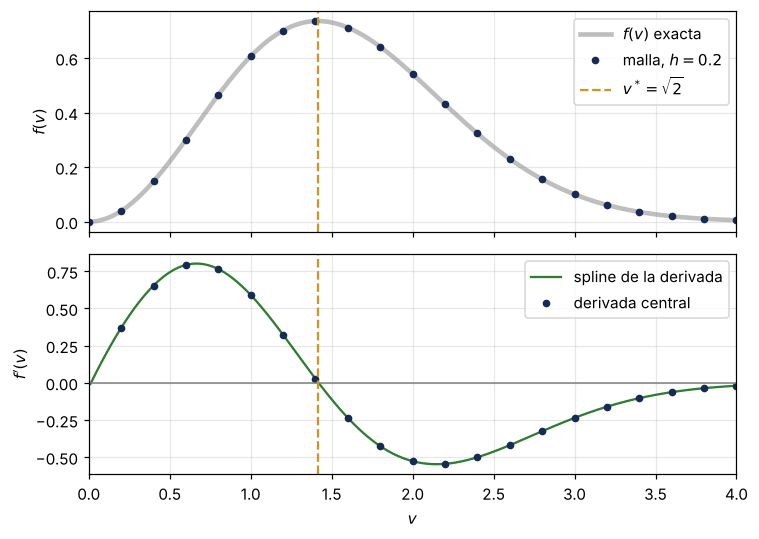

In [16]:
vi = v[1:-1]                           # puntos donde existe la derivada central
s_d = CubicSpline(vi, d)               # spline de la derivada numérica

candidatos = s_d.roots(extrapolate=False)
for r in candidatos:
    tipo = "máximo" if s_d(r, 1) < 0 else "mínimo"
    print(f"cero en v = {r:.6f}: f'' aprox. = {s_d(r, 1):8.4f} -> {tipo}")
v_spl = candidatos[s_d(candidatos, 1) < 0][0]

fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
vf = np.linspace(0, 4, 400)
ax[0].plot(vf, maxwell(vf), color=GRIS, lw=3, alpha=0.5, label="$f(v)$ exacta")
ax[0].plot(v, y, "o", ms=4, color=AZUL, label="malla, $h = 0.2$")
ax[0].axvline(v_ref, color=DORADO, ls="--", label=r"$v^* = \sqrt{2}$")
ax[0].set_xlim(0, 4); ax[0].set_ylabel("$f(v)$"); ax[0].legend()
ax[1].plot(vf[1:], s_d(vf[1:]), color=VERDE, label="spline de la derivada")
ax[1].plot(vi, d, "o", ms=4, color=AZUL, label="derivada central")
ax[1].axhline(0, color=GRIS, lw=1); ax[1].axvline(v_ref, color=DORADO, ls="--")
ax[1].set_xlabel("$v$"); ax[1].set_ylabel("$f'(v)$"); ax[1].legend()
plt.tight_layout(); plt.show()

### 5.4 Precisión al refinar la malla

La tabla compara las tres aproximaciones con mallas cada vez más finas, y agrega una cuarta: el spline de la función misma, cuya derivada se obtiene con `s.derivative()`, sin pasar por la derivada central.

In [17]:
def errores_maximo(h):
    """Errores de las cuatro aproximaciones del máximo con paso h."""
    v = np.arange(0.0, 6.0 + h/2, h)
    y = maxwell(v)
    d = derivada_central(y, h)
    s_d = CubicSpline(v[1:-1], d)                       # spline de la derivada
    r = s_d.roots(extrapolate=False)
    e_spl_d = abs(r[s_d(r, 1) < 0][0] - v_ref)
    ds = CubicSpline(v, y).derivative()                 # derivada del spline de f
    r = ds.roots(extrapolate=False)
    r = r[(ds(r, 1) < 0) & (r > 0.5)]
    return [abs(v[np.argmax(y)] - v_ref), abs(cero_lineal(v[1:-1], d) - v_ref),
            e_spl_d, abs(r[0] - v_ref)]

pasos = [0.4, 0.2, 0.1, 0.05]
tabla = np.array([errores_maximo(h) for h in pasos])
print("    h     arreglo   lineal    spline de d   spline de f")
for h, fila in zip(pasos, tabla):
    print(f"{h:6.2f} " + "".join(f"{e:11.2e}" for e in fila))
print("\nrazón entre errores consecutivos")
print(np.round(tabla[:-1]/tabla[1:], 2)[:, 1:])

    h     arreglo   lineal    spline de d   spline de f
  0.40    1.86e-01   2.88e-02   2.05e-02   2.51e-04
  0.20    1.42e-02   6.40e-03   4.74e-03   8.81e-05
  0.10    1.42e-02   1.72e-03   1.18e-03   2.92e-05
  0.05    1.42e-02   4.86e-04   2.95e-04   4.10e-06

razón entre errores consecutivos
[[4.5  4.33 2.85]
 [3.73 4.02 3.02]
 [3.53 4.   7.12]]


El mayor valor del arreglo no mejora de manera regular: su error depende de dónde cae la malla. El cero lineal y el spline de la derivada mejoran con razón $\approx 4$, es decir, con orden 2, aunque un spline cúbico interpola con mucho mejor orden: el error lo fija la **derivada central**, de orden 2, que alimenta al spline. Un método es tan preciso como su eslabón más débil. El spline de la función misma evita ese eslabón y tiene errores mucho menores.

### 5.5 Máximos y mínimos alternados

El oscilador amortiguado del Taller 7, $x(t) = e^{-\gamma t}\cos(\omega t)$, tiene varios extremos en el intervalo. Los ceros de la derivada los dan todos, y el signo de la segunda derivada los clasifica. Analíticamente, $\dot{x} = 0$ cuando $\tan(\omega t) = -\gamma/\omega$; el primer extremo después de $t = 0$ está en $t = 0.4874$ s.

In [18]:
gamma, omega = 0.5, 2*np.pi
h = 0.02
t = np.arange(0.0, 3.0 + h/2, h)
x = np.exp(-gamma*t)*np.cos(omega*t)

s_x = CubicSpline(t, x)                # spline de la posición
ds = s_x.derivative()                  # su derivada: la velocidad
for r in ds.roots(extrapolate=False):
    print(f"t = {r:.4f} s:  x = {s_x(r):8.4f} m  ->  {'máximo' if ds(r, 1) < 0 else 'mínimo'}")

t = 0.4874 s:  x =  -0.7813 m  ->  mínimo
t = 0.9874 s:  x =   0.6085 m  ->  máximo
t = 1.4874 s:  x =  -0.4739 m  ->  mínimo
t = 1.9874 s:  x =   0.3690 m  ->  máximo
t = 2.4874 s:  x =  -0.2874 m  ->  mínimo
t = 2.9874 s:  x =   0.2238 m  ->  máximo


<div style="border-left: 5px solid #162A54; background-color: #EEF1F7; padding: 10px 14px; margin: 8px 0;">

**Búsqueda sin derivadas.** Si no se dispone de $f'$ ni se quiere estimar, existen métodos que comparan solo valores de la función, como la búsqueda por sección áurea, que reduce el intervalo en un factor fijo en cada paso y es el análogo de la bisección para extremos. Comparar valores de $f$ tiene un límite: cerca de un máximo $f$ es casi plana, y la posición suele quedar limitada a unas 8 cifras en doble precisión. Por esa razón, en esta semana los máximos se buscan como ceros de la derivada.

</div>

<div style="border: 2px solid #C9972C; background-color: #FBF6EA; padding: 10px 14px; margin: 8px 0;">

**Ejercicio de calentamiento 3 (no calificado): rapidez más probable en una malla gruesa**

En la celda siguiente, la tabla contiene la distribución de Maxwell-Boltzmann con paso $h = 0.5$.

1. Obtenga la derivada central en los puntos interiores.
2. Construya el spline de esa derivada y obtenga el máximo y el valor de $f''$ en ese punto.
3. Compare con $f''(\sqrt{2}) = -4/e \approx -1.47$, valor que se obtiene derivando $f'(v)$ de la sección 5.1.

**Debe obtener:** $v^* \approx 1.444$ (error $\approx 2.9\times10^{-2}$) y $f'' \approx -1.18$.

</div>

In [ ]:
# Tabla del Ejercicio 3
v3 = np.arange(0.0, 6.5, 0.5)
y3 = maxwell(v3)

# TODO: obtenga el máximo y el valor de f'' con el spline de la derivada (sección 5.3)

## 6. Taller 8: la radiación de cuerpo negro


### A. Enunciado y requisitos

La radiancia espectral de un cuerpo negro a temperatura $T$ está dada por la **ley de Planck**:

$$B_\lambda(\lambda, T) = \frac{2hc^2}{\lambda^5}\,\frac{1}{e^{hc/(\lambda k_B T)} - 1} ,$$

donde $B_\lambda$ es la potencia emitida por unidad de área, de ángulo sólido y de longitud de onda [W m⁻² sr⁻¹ m⁻¹], $\lambda$ la longitud de onda [m], $T$ la temperatura [K], $h = 6.62607015\times10^{-34}$ J s la constante de Planck, $c = 299792458$ m/s la rapidez de la luz en el vacío y $k_B = 1.380649\times10^{-23}$ J/K la constante de Boltzmann. El factor $2hc^2/\lambda^5$ cuenta los modos electromagnéticos con su energía y el factor con el exponencial es la ocupación de esos modos. Estas tres constantes son exactas en el Sistema Internacional.

**Variable adimensional.** Con $x = hc/(\lambda k_B T)$, la razón entre la energía de un fotón y la energía térmica, el espectro queda

$$B_\lambda \propto \frac{x^5}{e^x - 1} .$$

**Ley de desplazamiento de Wien.** El máximo del espectro cumple $dB_\lambda/dx = 0$, que se reduce a

$$x = n\left(1 - e^{-x}\right), \qquad n = 5 ,$$

ecuación trascendente sin solución en funciones elementales, con la raíz trivial $x = 0$ y una raíz positiva $x_5$. Esa raíz fija la constante de Wien $b$:

$$\lambda_{\max}\,T = b = \frac{hc}{k_B\,x_5} .$$

Si el espectro se expresa por unidad de frecuencia, $B_\nu \propto x^3/(e^x - 1)$, y el máximo cumple la misma ecuación con $n = 3$.

**Ley de Stefan-Boltzmann.** La potencia total emitida por unidad de área es $M = \int_0^\infty \pi B_\lambda\,d\lambda = \sigma T^4$, con

$$\sigma = \frac{2\pi k_B^4}{h^3 c^2}\,I, \qquad I = \int_0^\infty \frac{x^3}{e^x - 1}\,dx ,$$

donde $\sigma$ es la constante de Stefan-Boltzmann [W m⁻² K⁻⁴] e $I$ una integral pura, cuyo valor exacto es $\pi^4/15$. Es una integral impropia. El cambio de variable $x = t/(1 - t)$, con $dx = dt/(1-t)^2$, la lleva al intervalo finito $[0, 1]$:

$$I = \int_0^1 \frac{x(t)^3}{e^{x(t)} - 1}\,\frac{dt}{(1 - t)^2} .$$

**El taller tiene tres partes:**

| Parte | Lenguaje | Qué se hace |
|---|---|---|
| B | Fortran | Módulo con tres métodos para hallar ceros; constante de Wien |
| C | Fortran | Módulo de Romberg del Taller 7 con un integrando nuevo; constante de Stefan-Boltzmann |
| D | Python | Máximo del espectro solar en una malla, con spline, comparado con la ley de Wien |

**Requisitos generales**

1. Todo el trabajo, incluido este notebook, se guarda en una carpeta llamada `taller_cuerpo_negro`, con los nombres de archivo que se indican en cada parte. El archivo `modulo_romberg.f90` del Taller 7 se copia en esa carpeta.
2. Se usa doble precisión: `real(dp)` en Fortran y `float` (64 bits) en Python.
3. Los métodos para hallar ceros tienen un máximo de 100 iteraciones y terminan con un mensaje si no convergen. Romberg conserva el límite de niveles del Taller 7.
4. La bisección comprueba el cambio de signo antes de iterar. Newton y secante se detienen con un mensaje si el denominador es nulo.
5. Se compila con `-fcheck=bounds`.
6. Los números reales de los archivos `.dat` se escriben con formato `es24.16`, y los identificadores y conteos como enteros.

**Qué se entrega**

- En la carpeta del repositorio: los programas, los archivos de datos, la figura y este notebook, con la celda de verificación en 5 de 5 PASS y las respuestas de la sección E en celdas Markdown al final.
- En Moodle: el reporte de una página y el enlace a la carpeta.

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**No está permitido** usar `scipy.optimize`, `scipy.integrate`, `np.gradient`, `np.trapz` ni funciones de biblioteca que hallen ceros, integren o deriven. `CubicSpline`, con sus métodos `.roots()` y `.derivative()`, se permite solo en la Parte D; las diferencias centrales se programan. Los métodos se programan a partir de las secciones 2 a 5. Cada estudiante sustentará su programa.

</div>

### B. Parte Fortran: constante de Wien

**Actividades**

1. Escriba `modulo_ceros.f90` con la función $F(x) = x - n(1 - e^{-x})$, su derivada y los métodos de bisección, Newton y secante. La organización en procedimientos es decisión suya; $n$ se pasa como argumento y debe respetar las reglas de la Semana 6.
2. Escriba `programa_wien.f90`, que use ese módulo para hallar $x_5$ y $x_3$ con tolerancia $\varepsilon = 10^{-10}$, con estos datos iniciales fijos:

| Método | Datos iniciales | Parada |
|---|---|---|
| Bisección | $[a, b] = [1, 10]$ | $b - c \le \varepsilon$ (sección 2) |
| Newton | $x_0 = 10$ | $\lvert x_{k+1} - x_k\rvert < \varepsilon$ |
| Secante | $x_0 = 10$, $x_1 = 9$ | $\lvert x_{k+1} - x_k\rvert < \varepsilon$ |

3. Repita Newton para $n = 5$ con $x_0 = 0.5$, y explique el resultado en el reporte.
4. Calcule la constante de Wien $b$ con $x_5$ obtenido por Newton.
5. Registre cada iteración de los tres métodos con $n = 5$ para analizar la convergencia. Las iteraciones de cada método se numeran desde 1 y en orden: la primera es la que produce el primer valor nuevo ($c_1$ en bisección, $x_1$ en Newton, $x_2$ en la secante).

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `modulo_ceros.f90` | Función, derivada y los tres métodos, con conteo de iteraciones |
| `programa_wien.f90` | Usa el módulo; escribe los tres archivos `.dat` de esta parte |
| `resultado_wien.dat` | 7 filas: $n$, método, raíz, iteraciones. Método: 1 bisección, 2 Newton, 3 secante, para $n = 5$ y $n = 3$; la fila 7 es $n = 5$, método 4 (Newton con $x_0 = 0.5$) |
| `iteraciones_wien.dat` | Una fila por iteración con $n = 5$: método (1 a 3), número de iteración, valor de $x$ |
| `constante_wien.dat` | Una línea: $x_5$, $x_3$, $b$ [m K] |

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** La bisección para $n = 5$ debe usar el número de iteraciones que predice la fórmula de la sección 2. Calcúlelo antes de ejecutar el programa: si no coincide, revise el criterio de parada.

</div>

In [ ]:
# Compila y ejecuta la Parte B (ejecute esta celda cuando sus archivos estén listos)
!gfortran -fcheck=bounds -o programa_wien modulo_ceros.f90 programa_wien.f90 && ./programa_wien

### C. Parte Fortran: constante de Stefan-Boltzmann

**Actividades**

1. Agregue a su `modulo_romberg.f90` del Taller 7 los integrandos de esta parte, sin cambiar la integración ni su criterio de parada. Los extremos $t = 0$ y $t = 1$ deben dar el límite correcto del integrando, que es cero en ambos.
2. Escriba `programa_sigma.f90`, que calcule $I$ en $t \in [0, 1]$ con tolerancia $10^{-8}$ y obtenga $\sigma$.
3. Calcule también $\int_0^{100} x^3/(e^x - 1)\,dx$ con el mismo Romberg y la misma tolerancia, **sin** cambio de variable.
4. Compare los dos resultados con $\pi^4/15$ y explique en el reporte lo que ocurre en el paso 3.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `modulo_romberg.f90` | Módulo del Taller 7 con los integrandos nuevos |
| `programa_sigma.f90` | Usa el módulo; escribe el archivo `.dat` de esta parte |
| `resultado_sigma.dat` | Dos filas, $k_{\text{final}}$, evaluaciones, integral, $\sigma$: fila 1 con cambio de variable, fila 2 sin cambio de variable. El nivel $k = 0$ es el trapecio inicial y las evaluaciones son $2^k + 1$ |

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Consejo.** Para $t$ cercano a 1, $x$ es tan grande que $e^x$ desborda la doble precisión a partir de $x \approx 709$. El integrando es prácticamente cero mucho antes: decida a partir de qué valor de $x$ puede devolver cero.

</div>

In [ ]:
# Compila y ejecuta la Parte C (ejecute esta celda cuando sus archivos estén listos)
!gfortran -fcheck=bounds -o programa_sigma modulo_romberg.f90 programa_sigma.f90 && ./programa_sigma

### D. Parte Python: máximo del espectro solar

Se modela el Sol como un cuerpo negro a $T = 5772$ K. El espectro se muestrea en una malla uniforme de longitudes de onda en $[100, 3000]$ nm, con paso $\Delta\lambda$.

**Actividades**

1. Escriba `maximo_espectro.py`. Construya $B_\lambda$ para $\Delta\lambda = 100, 50, 25$ y $12.5$ nm.
2. Para cada malla, obtenga $\lambda_{\max}$ de tres maneras: (a) mayor valor del arreglo; (b) cero del spline de la derivada central; (c) cero de la derivada del spline de $B_\lambda$. En (b) y (c), conserve los ceros donde la segunda derivada es negativa y, si queda más de uno, el más cercano al resultado de (a): en una malla gruesa el spline oscila y puede producir ceros espurios.
3. Lea $b$ de `constante_wien.dat` y obtenga el error absoluto en nm de cada resultado frente a $\lambda_{\max} = b/T$.
4. Escriba `maximo_espectro.dat` y grafique en `espectro_solar.png` el espectro de la malla de 25 nm, con $\lambda_{\max}$ marcado. Agregue en la misma figura el $\lambda$ que corresponde al máximo en frecuencia, $\lambda = hc/(k_B T x_3)$.

**Qué preparar**

| Archivo | Contenido |
|---|---|
| `maximo_espectro.py` | Construye los datos, halla los máximos, escribe los archivos y la figura |
| `maximo_espectro.dat` | Cuatro filas, una por $\Delta\lambda$: $\Delta\lambda$ [nm], error (a), error (b), error (c) [nm] |
| `espectro_solar.png` | Espectro con $\lambda_{\max}$ y el $\lambda$ del máximo en frecuencia |

In [ ]:
# Ejecuta la Parte D (ejecute esta celda cuando su archivo esté listo)
!python maximo_espectro.py

### E. Preguntas de interpretación y reporte

Responda en celdas Markdown al final de este notebook, con los números de sus archivos:

1. **Costo de los métodos.** Compare las iteraciones de los tres métodos con $n = 5$. Con `iteraciones_wien.dat`, estime el orden de Newton y de la secante.
2. **Valor inicial.** ¿A qué valor llega Newton desde $x_0 = 0.5$? ¿Por qué es una raíz correcta de la ecuación, pero no la respuesta al problema físico?
3. **Parada prematura.** En la Parte C, ¿qué valor da Romberg en $[0, 100]$ y en qué nivel se detiene? Explique, con los puntos que evalúa en sus primeros niveles, por qué el criterio de la diagonal se cumple sin que la integral haya convergido. Proponga una comprobación adicional.
4. **Eslabón más débil.** En la Parte D, ¿con qué razón bajan los errores de (b) y de (c) al reducir $\Delta\lambda$ a la mitad? ¿Qué limita la precisión de (b)? ¿Por qué el error de (a) no baja en estas mallas?
5. **Dos máximos.** ¿Por qué el máximo en longitud de onda y el máximo en frecuencia no corresponden al mismo color? ¿Cuál de los dos es "el" color del Sol?

**Reporte (una página, plantilla del curso).** Las secciones de contexto físico, método y resultado se refieren a la constante de Wien y al máximo del espectro (Partes B y D). La Parte C puede alimentar la sección de obstáculo o decisión de implementación. El reporte es una síntesis y no repite las cinco respuestas.

### F. Verificación

La celda siguiente **no debe modificarse**. Lee los archivos que escribieron sus programas, recalcula de forma independiente los valores de referencia, y comprueba la forma de cada archivo. También avisa si un archivo parece anterior a su código. El taller exige los cinco PASS.

In [ ]:
# ==================== VERIFICACIÓN DEL TALLER 8 Y 9 (no modificar) ====================
import os
import numpy as np
from scipy.interpolate import CubicSpline as _CS

H_, C_, KB_ = 6.62607015e-34, 299792458.0, 1.380649e-23

def raiz_referencia(n):
    x = float(n)
    for _ in range(200):
        x = n*(1 - np.exp(-x))
    return x

X5, X3 = raiz_referencia(5), raiz_referencia(3)
B_REF = H_*C_/(KB_*X5)
I_REF = np.pi**4/15
S_REF = 2*np.pi*KB_**4/(H_**3*C_**2)*I_REF
ITER_ESPERADAS = {(5,1):37, (5,2):4, (5,3):5,
                  (3,1):37, (3,2):5, (3,3):6}

_avisados = set()
def tabla(dat, fuentes, forma=None):
    for ruta in [dat, *fuentes]:
        if not os.path.isfile(ruta):
            raise ValueError(f"no existe {ruta}; ejecute desde la carpeta del taller")
    antiguos = [f for f in fuentes if os.path.getmtime(dat) < os.path.getmtime(f)]
    if antiguos and dat not in _avisados:
        print(f"[AVISO] {dat} parece anterior a su fuente; vuelva a generar si editó el código.")
        _avisados.add(dat)
    t = np.loadtxt(dat, ndmin=2)
    if forma is not None and t.shape != forma:
        raise ValueError(f"{dat}: forma {t.shape}; se espera {forma}")
    if not np.all(np.isfinite(t)):
        raise ValueError(f"{dat}: contiene NaN o infinitos")
    return t

def enteros(a, nombre):
    if not np.all(a == np.floor(a)):
        raise ValueError(f"{nombre}: se requieren valores enteros")

def resultados_wien():
    t = tabla('resultado_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (7,4))
    enteros(t[:,[0,1,3]], 'n, método e iteraciones')
    claves = [tuple(map(int, fila[:2])) for fila in t[:6]]
    if len(set(claves)) != 6 or set(claves) != set(ITER_ESPERADAS):
        raise ValueError('debe aparecer una vez cada combinación de n=5,3 y método=1,2,3')
    if tuple(t[6,:2]) != (5,4):
        raise ValueError('la fila 7 debe identificar n=5, método=4')
    if np.any((t[:,3] < 1) | (t[:,3] > 100)):
        raise ValueError('conteos fuera de 1 a 100')
    return t

def constantes():
    t = tabla('constante_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (1,3))[0]
    if abs(t[0]-X5)>2e-10 or abs(t[1]-X3)>2e-10:
        raise ValueError('x5 o x3 incorrectos en constante_wien.dat')
    if abs(t[2]-B_REF)/B_REF > 1e-9:
        raise ValueError('constante de Wien incorrecta')
    return t

resultados = []
def caso(nombre, funcion):
    try:
        detalle = funcion()
        ok = True
    except Exception as e:
        ok, detalle = False, str(e)
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f" -> {detalle}" if detalle else ''))

def c1():
    t = resultados_wien()
    for n, m, raiz, it in t[:6]:
        ref = X5 if n == 5 else X3
        if abs(raiz-ref)>2e-10:
            raise ValueError(f'n={n:g}, método={m:g}: raíz incorrecta')
        esperado = ITER_ESPERADAS[int(n),int(m)]
        if it != esperado:
            raise ValueError(f'n={n:g}, método={m:g}: {it:g} iteraciones; se esperan {esperado}')
    return f'x5={X5:.10f}, x3={X3:.10f}; conteos correctos'

def historia_referencia(m):
    # Recurrencias independientes para verificar los registros de n=5.
    f = lambda x: x-5*(1-np.exp(-x))
    df = lambda x: 1-5*np.exp(-x)
    a,b,prev = 1.0,10.0,10.0
    x = {1:0., 2:10., 3:9.}[m]
    valores=[]
    for _ in range(ITER_ESPERADAS[5,m]):
        if m==1:
            z=(a+b)/2
            if f(a)*f(z)<=0: b=z
            else: a=z
        elif m==2: z=x-f(x)/df(x)
        else: z=x-f(x)*(x-prev)/(f(x)-f(prev))
        valores.append(z)
        prev,x=x,z
    return np.array(valores)

def c2():
    t = tabla('iteraciones_wien.dat', ['modulo_ceros.f90','programa_wien.f90'])
    if t.shape[1]!=3: raise ValueError('iteraciones_wien.dat debe tener tres columnas')
    enteros(t[:,:2], 'método y contador')
    if set(t[:,0])!={1,2,3}: raise ValueError('faltan métodos o hay identificadores inválidos')
    for m in range(1,4):
        filas=t[t[:,0]==m]
        ref=historia_referencia(m)
        if len(filas)!=len(ref): raise ValueError(f'método {m}: número de registros incorrecto')
        if not np.array_equal(filas[:,1], np.arange(1,len(ref)+1)):
            raise ValueError(f'método {m}: use contadores consecutivos desde 1, en orden')
        if not np.allclose(filas[:,2],ref,atol=2e-13,rtol=2e-14):
            raise ValueError(f'método {m}: trayectoria incorrecta o pocas cifras en el archivo')
    return 'tres historiales completos'

def c3():
    x5,x3,b=constantes()
    t=resultados_wien()
    if abs(t[6,2])>1e-8: raise ValueError('Newton desde 0.5 debe llegar a la raíz trivial')
    return f'b={b:.9e} m K; raíz trivial comprobada'

def c4():
    t=tabla('resultado_sigma.dat', ['modulo_romberg.f90','programa_sigma.f90'], (2,4))
    enteros(t[:,:2], 'nivel y evaluaciones de Romberg')
    for k,ne,I,s in t:
        if k<0 or k>50 or ne<2:
            raise ValueError('nivel o conteo de Romberg inválido')
        if int(ne)!=2**int(k)+1:
            raise ValueError('use nivel k=0 para el trapecio inicial y cuente nodos únicos: 2**k+1')
        factor=2*np.pi*KB_**4/(H_**3*C_**2)
        if not np.isclose(s,factor*I,rtol=1e-8,atol=1e-30):
            raise ValueError('sigma no corresponde a la integral de su fila')
    if abs(t[0,2]-I_REF)>1e-8 or abs(t[0,3]-S_REF)/S_REF>1e-8:
        raise ValueError('la integral transformada o sigma no alcanzan la precisión solicitada')
    prematura=100/6*(4*50**3/np.expm1(50)+100**3/np.expm1(100))
    if t[1,0]!=1 or not np.isclose(t[1,2],prematura,rtol=1e-6,atol=1e-18):
        raise ValueError('fila 2: debe mostrar la parada prematura en k = 1')
    return f'sigma={t[0,3]:.9e} W/m²/K⁴; parada prematura reproducida'

def c5():
    constantes()
    t=tabla('maximo_espectro.dat', ['maximo_espectro.py','constante_wien.dat'], (4,4))
    if not np.array_equal(t[:,0],[100.,50.,25.,12.5]):
        raise ValueError('use, en este orden, pasos de 100, 50, 25 y 12.5 nm')
    if np.any(t[:,1:]<0): raise ValueError('los errores absolutos no pueden ser negativos')
    ref=B_REF/5772*1e9
    for fila in t:
        dl=fila[0]
        l=np.arange(100.,3000.+dl/2,dl)
        B=1/l**5/np.expm1(H_*C_/(l*1e-9*KB_*5772))
        la=l[np.argmax(B)]
        def cero(s):
            r=s.roots(extrapolate=False)
            r=r[np.isfinite(r)]
            r=r[s(r,1)<0]
            if len(r)==0: raise ValueError('no se encontró candidato a máximo')
            return r[np.argmin(abs(r-la))]
        esperados=[abs(la-ref),
            abs(cero(_CS(l[1:-1],(B[2:]-B[:-2])/(2*dl)))-ref),
            abs(cero(_CS(l,B).derivative())-ref)]
        for nombre,val,esp in zip(['a','b','c'],fila[1:],esperados):
            if abs(val-esp)>1e-4+0.01*esp:
                raise ValueError(f'paso {dl:g} nm, método {nombre}: error incompatible')
    if not os.path.isfile('espectro_solar.png'):
        raise ValueError('falta espectro_solar.png')
    return 'cuatro mallas correctas'

caso('1. Raíces e iteraciones de los tres métodos', c1)
caso('2. Historiales de iteración y convergencia', c2)
caso('3. Constante de Wien y Newton desde x0=0.5', c3)
caso('4. Stefan–Boltzmann y parada prematura', c4)
caso('5. Máximo del espectro solar en cuatro mallas', c5)
print(f'\nResultado: {sum(resultados)} de {len(resultados)} PASS')